In [ ]:
# Charles Prince, Cheng Guo
# CSDS 447 - Class Project
# Demo 1 on Llama Models

# Dataset: SciQ (https://huggingface.co/datasets/allenai/sciq)
# Model 1: Llama-3.2-1B-Instruct (https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct)
# Model 2: Llama-3.2-3B-Instruct (https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct)
# Remember to change MODEL_NAME and OUTPUT_FILE and BATCH_SIZE

In [ ]:
# Global Constants and Parameters
TEMPERATURE = 0.3
MAX_NEW_TOKENS = 64
BATCH_SIZE = 4 # 16 for 1B, 4 for 3B
QUESTIONS_PER_RUN = 10
BASE_SEED = 42
LETTERS = ["A", "B", "C", "D"]
MODEL_NAME = "meta-llama/Llama-3.2-3B-Instruct"
OUTPUT_FILE = "/content/drive/MyDrive/CSDS-447-FA26/447_Overconfidence_Project/llama32_3b_sciq_results.csv"

# Setup

In [ ]:
# Install Necessary Libraries
!pip install -q -U pandas transformers accelerate datasets huggingface_hub tqdm

In [ ]:
# Login to HuggingFace
from huggingface_hub import notebook_login
notebook_login()

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import Necessary Libraries
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
import random
from transformers import set_seed
import re
from tqdm.auto import tqdm
import pandas as pd

# Load Model and Dataset

In [ ]:
# Load Llama-3.2 Models
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# IMPORTANT for batched generation with Llama
tokenizer.padding_side = "left"

dtype = torch.float16 if torch.cuda.is_available() else torch.float32
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=dtype,
    device_map="auto"
)

model.eval()
print("Model loaded:", MODEL_NAME)
print("Device:", next(model.parameters()).device)

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Model loaded: meta-llama/Llama-3.2-3B-Instruct
Device: cuda:0


In [ ]:
# Load SciQ Dataset
dataset = load_dataset("allenai/sciq")
test_dataset = dataset["test"]
print(test_dataset)

Dataset({
    features: ['question', 'distractor3', 'distractor1', 'distractor2', 'correct_answer', 'support'],
    num_rows: 1000
})


# Build Prompts

In [ ]:
# Shuffle Answers
def prepare_question(example, question_index):
    """
    Shuffle the four answer choices ONCE for a question.

    Both support=False and support=True runs will use
    this exact same A/B/C/D ordering.
    """

    answers = [
        (example["correct_answer"], True),
        (example["distractor1"], False),
        (example["distractor2"], False),
        (example["distractor3"], False),
    ]

    # Reproducible question-specific shuffle
    rng = random.Random(BASE_SEED + question_index)
    rng.shuffle(answers)
    options = [answer for answer, _ in answers]
    correct_position = [is_correct for _, is_correct in answers].index(True)
    correct_letter = LETTERS[correct_position]
    return options, correct_letter

In [ ]:
# Format Questions to Build Prompt
def format_question(item, number, use_support):
    example = item["example"]
    options = item["options"]

    option_text = "\n".join(
        f"{letter}. {answer}"
        for letter, answer in zip(LETTERS, options)
    )

    if use_support:
        support_text = (
            f"Supporting information:\n"
            f"{example['support']}\n\n"
        )
    else:
        support_text = ""

    return f"""Q{number}:
            {support_text}Question:
            {example["question"]}

            Answer choices:
            {option_text}
            """

In [ ]:
# Build Answer Prompt
def build_answer_prompt(group, use_support):
    questions_text = "\n\n".join(
        format_question(item, i + 1, use_support)
        for i, item in enumerate(group)
    )

    return f"""Answer the following 10 multiple-choice science questions.

            For each question, select exactly one option letter: A, B, C, or D.

            IMPORTANT:
            - Output the LETTER only, not the answer text.
            - Do not copy the answer choice text.
            - Do not provide explanations.
            - You must provide exactly 10 answers.

            {questions_text}

            Return exactly in this format:
            1. A
            2. B
            3. C
            4. D
            5. A
            6. B
            7. C
            8. D
            9. A
            10. B
            """

In [ ]:
# Build Confidence Prompt
def build_confidence_prompt(group, use_support):
    questions_text = "\n\n".join(
        format_question(item, i + 1, use_support)
        for i, item in enumerate(group)
    )

    return f"""Read all of the multiple-choice science questions below.

            Judge how many of these questions you believe you could answer correctly.

            Consider each question before deciding on the total.

            Return only one line in exactly this format:

            CONFIDENT_COUNT: <number>

            The number must be a whole number and cannot be greater than the number of questions shown.

            Do not list confidence for individual questions.
            Do not provide explanations.
            Do not repeat the questions.

            {questions_text}

            CONFIDENT_COUNT:"""

# Generate and Parse Answer

In [ ]:
# Llama 3.2 Chat Format - BATCHED GENERATION
@torch.inference_mode()
def generate_batch(
    prompts,
    do_sample=True,
    max_new_tokens=MAX_NEW_TOKENS
):
    """
    Generate responses for multiple prompts at the same time.
    """

    chat_texts = []

    for prompt in prompts:
        messages = [
            {
                "role": "system",
                "content": (
                    "You are a science question-answering assistant. "
                    "Follow the user's requested output format exactly."
                )
            },
            {
                "role": "user",
                "content": prompt
            }
        ]

        chat_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        chat_texts.append(chat_text)

    inputs = tokenizer(
        chat_texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    device = next(model.parameters()).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[1]

    generation_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": do_sample,
        "use_cache": True,
        "num_beams": 1,
        "pad_token_id": tokenizer.eos_token_id,
        "eos_token_id": tokenizer.eos_token_id
    }

    if do_sample:
        generation_kwargs["temperature"] = TEMPERATURE
        generation_kwargs["top_p"] = 1.0

    outputs = model.generate(
        **inputs,
        **generation_kwargs
    )

    responses = []

    for output in outputs:
        generated_tokens = output[input_length:]

        response = tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        ).strip()

        responses.append(response)

    return responses

# Keep this function so your diagnostic cell still works
@torch.inference_mode()
def generate_response(prompt, run_seed):
    set_seed(run_seed)
    responses = generate_batch([prompt])
    return responses[0]

In [ ]:
# Parse the Answer
def parse_answers(response, group):
    answers = []

    for i, item in enumerate(group, start=1):

        match = re.search(
            rf"(?m)^\s*(?:Q)?{i}\s*[\.\):\-]\s*(.+?)\s*$",
            response,
            flags=re.IGNORECASE
        )

        if not match:
            answers.append(None)
            continue

        raw_answer = match.group(1).strip()

        # -----------------------------------------
        # Case 1: model returned A/B/C/D
        # -----------------------------------------
        letter_match = re.match(
            r"^([ABCD])\b",
            raw_answer,
            flags=re.IGNORECASE
        )

        if letter_match:
            answers.append(
                letter_match.group(1).upper()
            )
            continue

        # -----------------------------------------
        # Case 2: model returned answer text
        # -----------------------------------------
        def normalize(text):
            text = str(text).strip().lower()
            text = re.sub(r"\s+", " ", text)
            text = re.sub(r"[.,;:!?]+$", "", text)
            return text

        answer_text = normalize(raw_answer)

        option_map = {
            letter: normalize(option)
            for letter, option in zip(
                LETTERS,
                item["options"]
            )
        }

        # Exact text match first
        exact_matches = [
            letter
            for letter, option_text in option_map.items()
            if answer_text == option_text
        ]

        if len(exact_matches) == 1:
            answers.append(exact_matches[0])
            continue

        # Unique partial match, e.g.
        # "testes" -> "the testes"
        # "alpha" -> "alpha centauri"
        partial_matches = [
            letter
            for letter, option_text in option_map.items()
            if (
                answer_text in option_text
                or option_text in answer_text
            )
        ]

        if len(partial_matches) == 1:
            answers.append(partial_matches[0])
            continue

        # Could not safely determine an option
        answers.append(None)

    return answers

In [ ]:
# Parse Confident Count
def parse_confidence_count(response):
    # Preferred format:
    # CONFIDENT_COUNT: 7
    match = re.search(
        r"CONFIDENT_COUNT\s*:\s*(\d+)",
        response,
        flags=re.IGNORECASE
    )

    if match:
        value = int(match.group(1))

        if 0 <= value <= QUESTIONS_PER_RUN:
            return value

    # Because the prompt itself ends in "CONFIDENT_COUNT:",
    # the generated completion may simply be "7".
    match = re.fullmatch(
        r"\s*(\d+)\s*",
        response
    )

    if match:
        value = int(match.group(1))

        if 0 <= value <= QUESTIONS_PER_RUN:
            return value

    return None

# Run and Collect Results

In [ ]:
# Run Experiment Using Batches
set_seed(BASE_SEED)

# =========================================================
# Step 1: Prepare all questions
# =========================================================

prepared_questions = []

for i in range(len(test_dataset)):
    example = test_dataset[i]

    # Shuffle choices ONCE so both support conditions
    # use the exact same A/B/C/D ordering.
    options, gold_answer = prepare_question(
        example,
        question_index=i
    )

    prepared_questions.append({
        "question_index": i,
        "example": example,
        "options": options,
        "ground_truth": gold_answer
    })


# =========================================================
# Step 2: Group questions into groups of 10
# =========================================================

# For SciQ test set this should divide evenly.
# If you later use a dataset that does not divide evenly,
# the final smaller group will still be processed.
groups = [
    prepared_questions[i:i + QUESTIONS_PER_RUN]
    for i in range(
        0,
        len(prepared_questions),
        QUESTIONS_PER_RUN
    )
]

print("Questions:", len(prepared_questions))
print("Groups:", len(groups))
print("Questions per group:", QUESTIONS_PER_RUN)


# =========================================================
# Step 3: Create jobs for both experimental conditions
# =========================================================

no_support_jobs = []
support_jobs = []

for group_index, group in enumerate(groups):

    # -----------------------------------------------------
    # WITHOUT SUPPORT
    # -----------------------------------------------------

    answer_prompt_no_support = build_answer_prompt(
        group=group,
        use_support=False
    )

    confidence_prompt_no_support = build_confidence_prompt(
        group=group,
        use_support=False
    )

    no_support_jobs.append({
        "group_index": group_index,
        "use_support": False,
        "group": group,

        # These are two completely separate prompts.
        "answer_prompt": answer_prompt_no_support,
        "confidence_prompt": confidence_prompt_no_support
    })


    # -----------------------------------------------------
    # WITH SUPPORT
    # -----------------------------------------------------

    answer_prompt_support = build_answer_prompt(
        group=group,
        use_support=True
    )

    confidence_prompt_support = build_confidence_prompt(
        group=group,
        use_support=True
    )

    support_jobs.append({
        "group_index": group_index,
        "use_support": True,
        "group": group,

        # Again, answer and confidence are separate prompts.
        "answer_prompt": answer_prompt_support,
        "confidence_prompt": confidence_prompt_support
    })


# Keep similar-length prompts together for more efficient batching.
jobs = no_support_jobs + support_jobs

print("Experimental conditions per group: 2")
print("Total group jobs:", len(jobs))
print("Total model calls:", len(jobs) * 2)
print("Batch size:", BATCH_SIZE)


# =========================================================
# Step 4: Generate ANSWERS and CONFIDENCE separately
# =========================================================

results = []

for start in tqdm(
    range(0, len(jobs), BATCH_SIZE),
    desc="Generating"
):

    end = min(
        start + BATCH_SIZE,
        len(jobs)
    )

    batch_jobs = jobs[start:end]

    # -----------------------------------------------------
    # 4A. ANSWER-ONLY GENERATION
    # -----------------------------------------------------

    answer_prompts = [
        job["answer_prompt"]
        for job in batch_jobs
    ]

    answer_responses = generate_batch(
        answer_prompts,
        do_sample=True,
        max_new_tokens=64
    )

    # -----------------------------------------------------
    # 4B. CONFIDENCE-ONLY GENERATION
    # -----------------------------------------------------

    confidence_prompts = [
        job["confidence_prompt"]
        for job in batch_jobs
    ]

    confidence_responses = generate_batch(
        confidence_prompts,
        do_sample=False,
        max_new_tokens=8
    )

    # -----------------------------------------------------
    # Step 5: Parse responses and save one row per question
    # -----------------------------------------------------

    for job, answer_response, confidence_response in zip(
        batch_jobs,
        answer_responses,
        confidence_responses
    ):

        group = job["group"]

        # Parse the 10 answer letters.
        predicted_answers = parse_answers(
            answer_response,
            group
        )

        # Parse the ONE group-level number from 0-10.
        confident_count = parse_confidence_count(
            confidence_response
        )

        # Store one result row for each individual question.
        #
        # All questions in the same group share the same
        # "confident_count", because confidence was asked
        # once for the entire group of 10.
        for position_in_group, (item, predicted_answer) in enumerate(
            zip(group, predicted_answers),
            start=1
        ):

            example = item["example"]
            options = item["options"]

            result = {
                "group_index": job["group_index"],
                "position_in_group": position_in_group,

                "question_index": item["question_index"],
                "use_support": job["use_support"],

                "question": example["question"],

                # Only save support text for the support condition.
                "support": (
                    example["support"]
                    if job["use_support"]
                    else ""
                ),

                "option_A": options[0],
                "option_B": options[1],
                "option_C": options[2],
                "option_D": options[3],

                "ground_truth": item["ground_truth"],
                "predicted_answer": predicted_answer,

                # Group-level confidence:
                # estimated number correct out of the 10 questions.
                "confident_count": confident_count,

                "temperature": TEMPERATURE,

                # Save both complete outputs for debugging.
                "answer_output": answer_response,
                "confidence_output": confidence_response
            }

            results.append(result)


# =========================================================
# Step 6: Report completion
# =========================================================

print()
print("Finished.")
print("Total question-level results:", len(results))

expected_results = (
    len(prepared_questions) * 2
)

print("Expected question-level results:", expected_results)

if len(results) == expected_results:
    print("Result count looks correct.")
else:
    print("WARNING: Result count does not match expected count.")

Questions: 1000
Groups: 100
Questions per group: 10
Experimental conditions per group: 2
Total group jobs: 200
Total model calls: 400
Batch size: 4


Generating:   0%|          | 0/50 [00:00<?, ?it/s]


Finished.
Total question-level results: 2000
Expected question-level results: 2000
Result count looks correct.


# Save Output to CSV

In [ ]:
# Put the two conditions for each question next to each other
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by=[
        "group_index",
        "use_support",
        "position_in_group"
    ]
).reset_index(drop=True)
print("Shape:", results_df.shape)

Shape: (2000, 16)


In [ ]:
# Save to CSV
results_df.to_csv(OUTPUT_FILE, index=False)
print("Saved to:", OUTPUT_FILE)

Saved to: /content/drive/MyDrive/CSDS-447-FA26/447_Overconfidence_Project/llama32_3b_sciq_results.csv


# Analyze Llama Result

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import Necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load results
OUTPUT_FILE = "/content/drive/MyDrive/CSDS-447-FA26/447_Overconfidence_Project/llama32_3b_sciq_results.csv"
df = pd.read_csv(OUTPUT_FILE)

In [ ]:
# Preprocessing
df["is_correct"] = (df["predicted_answer"] == df["ground_truth"])
with_support = df[df["use_support"] == True]
without_support = df[df["use_support"] == False]

In [ ]:
# Report Total accuracy
accuracy_with = with_support["is_correct"].mean() * 100
accuracy_without = without_support["is_correct"].mean() * 100
print(f"Accuracy WITH support:    {accuracy_with:.2f}%")
print(f"Accuracy WITHOUT support: {accuracy_without:.2f}%")

Accuracy WITH support:    86.30%
Accuracy WITHOUT support: 86.60%


In [ ]:
# Group-Level Confidence Analysis

# Confidence is now defined for a GROUP of questions:
#
# confident_count = how many questions out of the group
# the model thinks it can answer correctly.
#
# Therefore, confidence must be analyzed at the group level,
# not at the individual-question level.

group_results = (
    df.groupby(
        ["group_index", "use_support"],
        as_index=False
    )
    .agg(
        # Every row in the group has the same confident_count,
        # so just take the first one.
        confident_count=("confident_count", "first"),

        # Number actually answered correctly in the group.
        actual_correct=("is_correct", "sum"),

        # Normally 10, but keeping this makes the analysis
        # safe if a final group contains fewer than 10.
        group_size=("is_correct", "size")
    )
)

# ---------------------------------------------------------
# Additional useful group-level measurements
# ---------------------------------------------------------

# Positive:
# model thought it would get MORE correct than it actually did.
#
# Negative:
# model thought it would get FEWER correct than it actually did.
group_results["calibration_error"] = (
    group_results["confident_count"]
    - group_results["actual_correct"]
)

group_results["absolute_error"] = (
    group_results["calibration_error"].abs()
)

# Convert both estimates to percentages if useful later.
group_results["estimated_accuracy"] = (
    group_results["confident_count"]
    / group_results["group_size"]
    * 100
)

group_results["actual_accuracy"] = (
    group_results["actual_correct"]
    / group_results["group_size"]
    * 100
)


# Separate the two experimental conditions.
with_support_groups = group_results[
    group_results["use_support"] == True
].copy()

without_support_groups = group_results[
    group_results["use_support"] == False
].copy()


# ---------------------------------------------------------
# Confidence-count distributions
# ---------------------------------------------------------

with_counts = (
    with_support_groups["confident_count"]
    .value_counts()
    .reindex(range(0, 11), fill_value=0)
)

without_counts = (
    without_support_groups["confident_count"]
    .value_counts()
    .reindex(range(0, 11), fill_value=0)
)

print("Number of groups WITH support:", len(with_support_groups))
print("Number of groups WITHOUT support:", len(without_support_groups))
print()
print(group_results.head(10))

Number of groups WITH support: 100
Number of groups WITHOUT support: 100

   group_index  use_support  confident_count  actual_correct  group_size  \
0            0        False                8              10          10   
1            0         True               10               9          10   
2            1        False                8               8          10   
3            1         True                9               9          10   
4            2        False                8               8          10   
5            2         True                8               7          10   
6            3        False                8              10          10   
7            3         True                8               9          10   
8            4        False                8               6          10   
9            4         True                8               8          10   

   calibration_error  absolute_error  estimated_accuracy  actual_accuracy  
0            

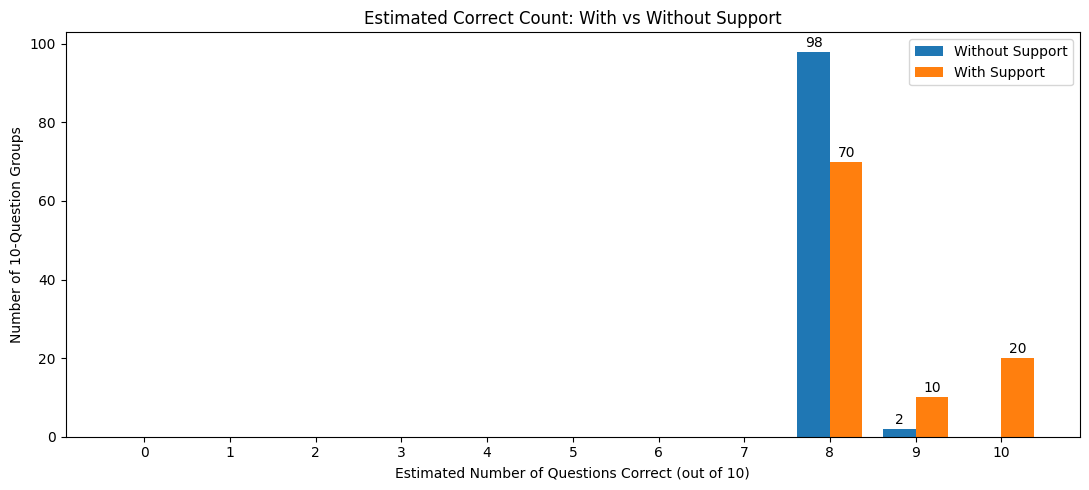

In [ ]:
# Plot Distribution of Estimated Number Correct
x = np.arange(0, 11)
width = 0.38
plt.figure(figsize=(11, 5))

# WITHOUT SUPPORT
plt.bar(
    x - width / 2,
    without_counts.values,
    width,
    label="Without Support"
)

# WITH SUPPORT
plt.bar(
    x + width / 2,
    with_counts.values,
    width,
    label="With Support"
)

# ---------------------------------------------------------
# Write count above each non-zero bar
# ---------------------------------------------------------

for xpos, count in zip(x - width / 2, without_counts.values):
    if count > 0:
        plt.text(xpos, count + 0.5, str(count), ha="center", va="bottom")

for xpos, count in zip(x + width / 2, with_counts.values):
    if count > 0:
        plt.text(xpos, count + 0.5, str(count), ha="center", va="bottom")

plt.xlabel("Estimated Number of Questions Correct (out of 10)")
plt.ylabel("Number of 10-Question Groups")
plt.title("Estimated Correct Count: With vs Without Support")
plt.xticks(range(0, 11))
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Actual Correct Count at Each Estimated Correct Count

calibration_by_estimate = (
    group_results
    .groupby(
        ["confident_count", "use_support"]
    )["actual_correct"]
    .mean()
    .unstack()
    .reindex(range(0, 11))
)

# Rename conditions for readability.
calibration_by_estimate = calibration_by_estimate.rename(
    columns={
        False: "Without Support",
        True: "With Support"
    }
)

print(
    "Average ACTUAL number correct for each "
    "ESTIMATED number correct:"
)
print()
print(calibration_by_estimate.round(2))

# ---------------------------------------------------------
# Also report overall group-level summary
# ---------------------------------------------------------

summary = (
    group_results
    .groupby("use_support")
    .agg(
        num_groups=("group_index", "count"),

        mean_estimated_correct=(
            "confident_count",
            "mean"
        ),

        mean_actual_correct=(
            "actual_correct",
            "mean"
        ),

        mean_calibration_error=(
            "calibration_error",
            "mean"
        ),

        mean_absolute_error=(
            "absolute_error",
            "mean"
        )
    )
    .rename(
        index={
            False: "Without Support",
            True: "With Support"
        }
    )
)

print()
print("Overall group-level summary:")
print()
print(summary.round(3))

Average ACTUAL number correct for each ESTIMATED number correct:

use_support      Without Support  With Support
confident_count                               
0                            NaN           NaN
1                            NaN           NaN
2                            NaN           NaN
3                            NaN           NaN
4                            NaN           NaN
5                            NaN           NaN
6                            NaN           NaN
7                            NaN           NaN
8                           8.64          8.47
9                           9.50          9.10
10                           NaN          8.95

Overall group-level summary:

                 num_groups  mean_estimated_correct  mean_actual_correct  \
use_support                                                                
Without Support         100                    8.02                 8.66   
With Support            100                    8.50             

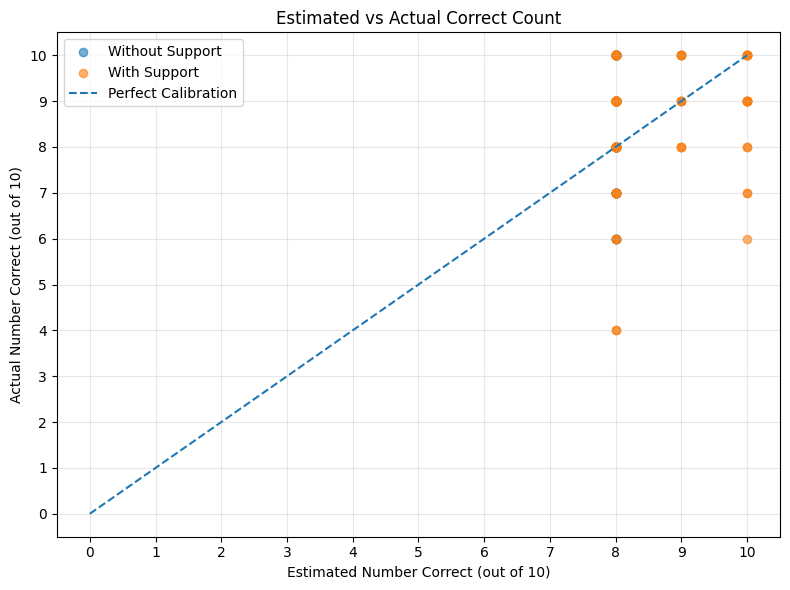

In [ ]:
# Plot group-level estimated vs actual correct count
plt.figure(figsize=(8, 6))
without_support_groups = group_results[group_results["use_support"] == False]
with_support_groups = group_results[group_results["use_support"] == True]

# Individual 10-question groups
plt.scatter(
    without_support_groups["confident_count"],
    without_support_groups["actual_correct"],
    alpha=0.6,
    label="Without Support"
)

plt.scatter(
    with_support_groups["confident_count"],
    with_support_groups["actual_correct"],
    alpha=0.6,
    label="With Support"
)

# Perfect calibration
plt.plot(
    [0, 10],
    [0, 10],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Estimated Number Correct (out of 10)")
plt.ylabel("Actual Number Correct (out of 10)")
plt.title("Estimated vs Actual Correct Count")
plt.xticks(range(0, 11))
plt.yticks(range(0, 11))
plt.xlim(-0.5, 10.5)
plt.ylim(-0.5, 10.5)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()